# LeetCode #155: Min Stack

https://leetcode.com/problems/min-stack/

## Comparison of Approaches

| Approach | Time | Space | What that means in practice |
|---|---|---|---|
| Brute Force | $O(n)$ for `getMin`, $O(1)$ otherwise | $O(n)$ | `getMin` looks through every value on the stack, so it slows down as the stack grows. |
| Single Stack with Pairs | $O(1)$ all ops | $O(n)$ | Every entry carries "the minimum so far" with it: always two numbers per value. |
| Two Stacks ★ | $O(1)$ all ops | $O(n)$ | A second stack records only new lows, so it's often much shorter than the main one. |

`n` is how many values are on the stack. $O(1)$ means an operation takes the same tiny amount of work whether the stack holds 3 values or 30,000. $O(n)$ means it grows with the stack: for `getMin` that's a full scan, for space it's one slot per value.

---

## Understanding the Methods

A **stack** is a pile: you add to the top (`push`), remove from the top (`pop`), and look at the top (`top`). The task is to also answer "what's the smallest value in the pile?" (`getMin`) just as quickly.

### Brute Force
Keep a normal stack and, when asked for the minimum, look at every value. Correct, but each `getMin` costs a full scan.

### Single Stack with Pairs
Push `(value, minimum including this value)` together. The minimum is then always stored on top. Simple and fast, but it stores a second number for every single value, even when the minimum never changes.

### Optimal: Two Stacks ★
Keep the main stack as normal, plus a **min stack** whose top is always the current minimum. On `push`, also push onto the min stack if the value is **less than or equal to** its top (a new low, or a tie with the current one). On `pop`, if the value leaving equals the min stack's top, pop that too. `getMin` just reads the min stack's top.

**Why this is better than Single Stack with Pairs:** same constant time for every operation, but the min stack only grows when a new low arrives, so on most inputs it holds far fewer entries than one per value.

**Constraints:**
* $-2^{31} \le$ `val` $\le 2^{31} - 1$
* `pop`, `top` and `getMin` are only ever called on a non-empty stack
* At most $3 \times 10^4$ calls in total

## Explain Like I'm a Newbie

### What the question is actually asking

Build a stack (a pile where you only touch the top) that can also tell you its smallest value instantly, at any moment, even after things have been popped off.

```
push(-2)   pile: -2           smallest: -2
push(0)    pile: -2 0         smallest: -2
push(-3)   pile: -2 0 -3      smallest: -3
pop()      pile: -2 0         smallest: -2   <- back to the old answer
```

### The one idea you need: remember the minimum as it was at each height

Keeping one variable `min` is easy while you're pushing. The problem is `pop`. When the -3 leaves, what was the minimum before it arrived? A single variable has already forgotten.

But a stack only ever removes the newest item. So the minimum after a pop is exactly the minimum from before that item was pushed. If you record the minimum every time it changes, in a second pile, popping just means stepping back one record.

### What that means in code

Keep two stacks. The **main stack** holds every value. The **min stack** holds the history of lows: its top is always the current minimum.

- `push(val)`: push onto the main stack. If the min stack is empty, or `val` is **less than or equal to** its top, push `val` there too.
- `pop()`: pop the main stack. If that value equals the min stack's top, pop the min stack as well.
- `getMin()`: read the min stack's top.

### Mistakes people make the first time

1. **Using `<` instead of `<=` on push.** It passes the LeetCode sample, then breaks on `push(0), push(1), push(0), pop(), getMin()`. The second 0 was never recorded, so popping it removes the only 0 from the min stack, and `getMin` finds nothing there.
2. **A single `min` variable.** Correct until the first pop of the minimum, then stuck on a value that's gone.
3. **Popping the min stack on every pop.** It only holds the lows, so it runs out early.
4. **Reading the min stack's top on the very first push.** It starts empty, so check for empty before comparing.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The thirty-second version

Where you should end up: *"Two stacks. The main one holds everything; the second holds the history of minimums, pushed whenever a value is less than or equal to the current minimum and popped when that value leaves. Its top is always the answer. Every operation is a push, pop or peek, so constant time."*

And then, unprompted: *"the one character that matters is `<=`. With `<`, duplicate minimums get lost and the second pop of a repeated minimum empties the min stack."*

---

### I slide the problem across the table

It's a design question: a class with `push`, `pop`, `top` and `getMin`, all in constant time.

> **You:** "So a normal stack, plus `getMin` answering the smallest value currently on it, in $O(1)$. Two things to pin down. Will `pop`, `top` or `getMin` ever be called on an empty stack? And can values repeat?"

Both are the right questions. The first decides whether I need error handling; the second is where this problem's bug lives. I'll say **"never on empty, and yes, duplicates are allowed."**

> **You:** "And the values span the whole 32-bit range, so I shouldn't do anything clever with arithmetic on them."

That's a sharp one, and I'll come back to it. I'll just say **"right, full int range."**

---

### Now tell me what's actually hard about it

Saying "two stacks" straight away tells me you've done this before. I'd rather hear why one variable isn't enough:

> **You:** "Tracking the minimum while pushing is trivial: one variable. The problem is popping. If the minimum leaves, I need the minimum of what's left, and a single variable has lost it. Scanning to find it again is $O(n)$."

> **You:** "But a stack is last in, first out. After a pop, the stack is exactly what it was before that push. So the minimum after a pop is the minimum from before that push. If I keep the history of minimums, popping is just stepping back one entry."

That's the insight, and it's what tells me the design came from the problem rather than from memory.

---

### Whiteboard the structures first

Before any method, I want to see what you're storing and why:

```
stack:     [-2, 0, -3]      every value, in push order
minStack:  [-2, -3]         the lows, in the order they happened
```

> **You:** "The main stack is the stack. The min stack's top is always the current minimum. It only gets a new entry when a value is a new low or ties the current one, so it's usually much shorter. The alternative is one stack of pairs, each value with the minimum at that point. Same speed, but it always stores two numbers per value. I'll go with two stacks."

Agree on that first and the methods nearly write themselves. Write `push` before the structures are settled and you'll usually rewrite it.

---

### Now the methods

```
push(val):
    stack.push(val)
    if minStack is empty or val <= minStack.top:
        minStack.push(val)
```

> **You:** "Less-than-or-equal. If I push 0, 1, 0, both zeros need to be on the min stack. With `<` only the first goes on, and when I pop the second 0, my equality check removes the only 0 from the min stack."

That's the sentence I want. Without it I'll ask *"push 0, 1, 0, pop, getMin: what happens?"* With `<`, the min stack is empty after that pop and `getMin` crashes.

```
pop():
    val = stack.pop()
    if val == minStack.top:
        minStack.pop()

top():    return stack.top
getMin(): return minStack.top
```

> **You:** "The pop only touches the min stack if the leaving value is the current minimum. Because of `<=`, every copy of a minimum on the main stack has a matching copy on the min stack, so this stays in step."

---

### Walk me through it before you say you're done

> **You:** "LeetCode's sequence: push -2, both stacks get it. Push 0: main only. Push -3: both, min stack is `[-2, -3]`. `getMin` reads -3. Pop removes -3 from main, it equals the min top, so the min stack goes back to `[-2]`. `top` is 0. `getMin` is -2."

Then the case from the clarifier: push 0, 1, 0. The min stack is `[0, 0]`. Pop removes a 0 from both, leaving `[0]`, and `getMin` is still 0. That's the duplicates question answered with the actual code.

---

### Then tell me where it breaks, before I ask

There isn't a wrong answer in it for the stated contract, and I'd rather you say that than invent one. What I want instead is the contract it leans on, and why you didn't use a trick:

> **You:** "It assumes the caller never pops or peeks an empty stack. Here that's guaranteed. In a library I'd check and throw, because right now Go and Rust would panic and Python would raise a bare `IndexError`."

> **You:** "There's a well-known trick that uses one stack and one variable, storing `val - min` instead of `val`. It saves space, but `val - min` can reach almost $2^{32}$ with the full int range, which overflows a 32-bit int. That's why I asked about the range. I'd only use it with 64-bit storage, and at that point it isn't saving anything."

That second point is exactly what I was saving the range question for.

---

### What would worry me

- **`<` on push**, and no answer when I hand you `0, 1, 0`.
- **Methods before structures**: writing `push` before saying what the min stack holds.
- **The `val - min` trick** presented as an improvement with no word about overflow.
- **Scanning in `getMin`**, which misses the whole point of the question.


## Solutions

### C#

In [ ]:
public class MinStack {
    // Every value, in push order
    private Stack<int> stack = new();
    // The history of minimums: its top is always the current minimum
    private Stack<int> minStack = new();

    public void Push(int val) {
        stack.Push(val);
        // <= not <: a tie with the current minimum must be recorded too. With <,
        // push 0, 1, 0 records one 0, and popping the second 0 would remove it.
        if (minStack.Count == 0 || val <= minStack.Peek())
            minStack.Push(val);
    }

    public void Pop() {
        int val = stack.Pop();
        // Only a leaving minimum changes the minimum; step back to the previous low
        if (val == minStack.Peek())
            minStack.Pop();
    }

    public int Top() => stack.Peek();

    public int GetMin() => minStack.Peek();
}

### Python

In [ ]:
class MinStack:
    def __init__(self):
        self.stack = []       # every value, in push order
        self.min_stack = []   # history of minimums: top is the current minimum

    def push(self, val: int) -> None:
        self.stack.append(val)
        # <= not <: a tie with the current minimum must be recorded too. With <,
        # push 0, 1, 0 records one 0, and popping the second 0 would remove it.
        if not self.min_stack or val <= self.min_stack[-1]:
            self.min_stack.append(val)

    def pop(self) -> None:
        val = self.stack.pop()
        # Only a leaving minimum changes the minimum; step back to the previous low
        if val == self.min_stack[-1]:
            self.min_stack.pop()

    def top(self) -> int:
        return self.stack[-1]

    def getMin(self) -> int:
        return self.min_stack[-1]

### Go

Go slices are used as stacks: `append` pushes, and `s[:len(s)-1]` pops by shortening the slice. The `main` function is only a local demo.

In [ ]:
package main

import "fmt"

type MinStack struct {
    stack    []int // every value, in push order
    minStack []int // history of minimums: last element is the current minimum
}

func Constructor() MinStack { return MinStack{} }

func (s *MinStack) Push(val int) {
    s.stack = append(s.stack, val)
    // <= not <: a tie with the current minimum must be recorded too. With <,
    // push 0, 1, 0 records one 0, and popping the second 0 would remove it.
    if len(s.minStack) == 0 || val <= s.minStack[len(s.minStack)-1] {
        s.minStack = append(s.minStack, val)
    }
}

func (s *MinStack) Pop() {
    val := s.stack[len(s.stack)-1]
    s.stack = s.stack[:len(s.stack)-1]
    // Only a leaving minimum changes the minimum; step back to the previous low
    if val == s.minStack[len(s.minStack)-1] {
        s.minStack = s.minStack[:len(s.minStack)-1]
    }
}

func (s *MinStack) Top() int   { return s.stack[len(s.stack)-1] }
func (s *MinStack) GetMin() int { return s.minStack[len(s.minStack)-1] }

// Local demo only; LeetCode calls the methods itself
func main() {
    ms := Constructor()
    ms.Push(-2); ms.Push(0); ms.Push(-3)
    fmt.Println(ms.GetMin()) // -3
    ms.Pop()
    fmt.Println(ms.Top())    // 0
    fmt.Println(ms.GetMin()) // -2
}

### Rust

`last().unwrap()` panics on an empty stack. That is acceptable here only because the problem promises `pop`, `top` and `getMin` are never called on an empty stack.

In [ ]:
pub struct MinStack {
    stack: Vec<i32>,     // every value, in push order
    min_stack: Vec<i32>, // history of minimums: last element is the current minimum
}

impl MinStack {
    pub fn new() -> Self {
        MinStack { stack: vec![], min_stack: vec![] }
    }

    pub fn push(&mut self, val: i32) {
        self.stack.push(val);
        // <= not <: a tie with the current minimum must be recorded too. With <,
        // push 0, 1, 0 records one 0, and popping the second 0 would remove it.
        if self.min_stack.is_empty() || val <= *self.min_stack.last().unwrap() {
            self.min_stack.push(val);
        }
    }

    pub fn pop(&mut self) {
        let val = self.stack.pop().unwrap();
        // Only a leaving minimum changes the minimum; step back to the previous low
        if val == *self.min_stack.last().unwrap() {
            self.min_stack.pop();
        }
    }

    pub fn top(&self) -> i32 { *self.stack.last().unwrap() }
    pub fn get_min(&self) -> i32 { *self.min_stack.last().unwrap() }
}

## Example Scenarios

### 1. Common Case — The LeetCode Sample
**Input:** `push(-2); push(0); push(-3); getMin(); pop(); top(); getMin()`

The min stack records -2, skips 0 (not a new low), then records -3, so `getMin` gives -3. Popping -3 removes it from both stacks, which leaves 0 on top of the main stack and -2 on top of the min stack. **Output:** `getMin` → `-3`, `top` → `0`, `getMin` → `-2`

### 2. Slightly Complex — Duplicate Minimums
**Input:** `push(2); push(2); push(1); pop(); getMin()`

Because the push test is "less than or equal", the second 2 is recorded on the min stack as well as the first. After the 1 is popped the minimum is 2 again, and if a 2 were popped next there would still be another 2 on the min stack to fall back on. **Output:** `getMin` → `2`

### 3. Edge Case: Time Factor — Every Operation O(1)
**Input:** `push(5); push(3); push(7); getMin(); push(1); getMin()`

`getMin` reads the top of the min stack and never scans the pile, so it costs the same with 3 values or 30,000. The 7 isn't a new low and is skipped; the 1 is, and becomes the new top. **Output:** `getMin` → `3`, then `getMin` → `1`

### 4. Edge Case: Space Factor — Strictly Decreasing Pushes
**Input:** `push(5); push(4); push(3); push(2); push(1)`

Every value is a new low, so every one goes on the min stack too, and it grows as tall as the main stack. That's the most memory this design can use: two copies of each value. **Output:** no return values (both stacks hold 5 entries)

### 5. Almost-Impossible but Plausible — Emptied Completely
**Input:** `push(1); push(2); pop(); pop()`

The 2 was never a new low, so popping it leaves the min stack alone; popping the 1 removes it from both. Both stacks end empty together, which is fine because the problem promises `top` and `getMin` won't be called on an empty stack. **Output:** no return values (both stacks empty)


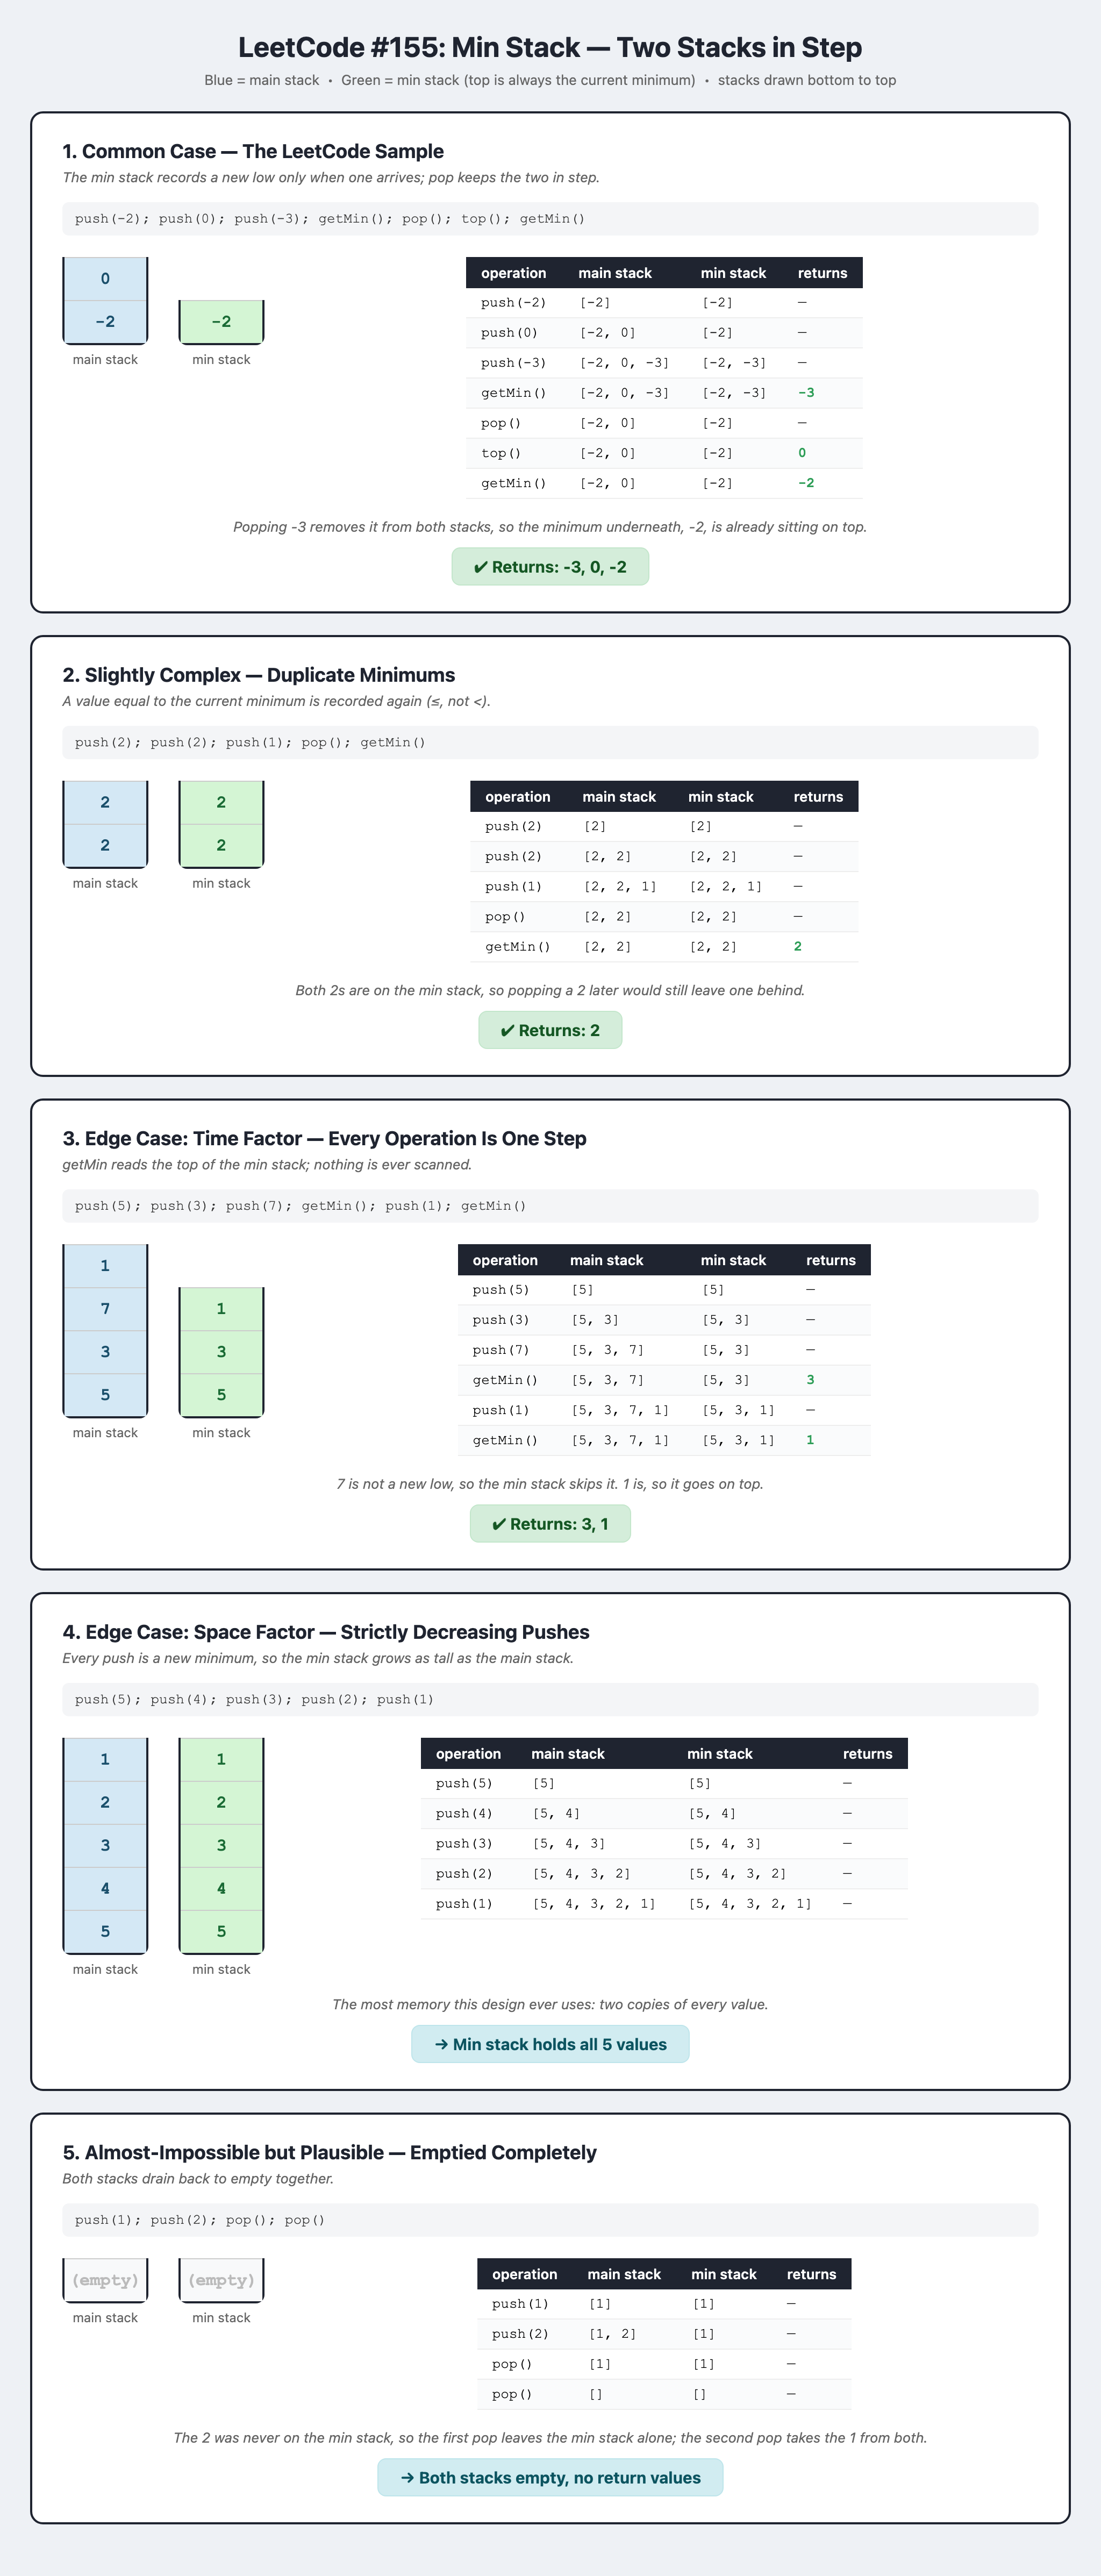